# Ảnh minh họa Nhiệm vụ 3
Chạy trên CPU trong workspace có artifacts pilot và VN100. Hình đối chiếu dùng ảnh gốc từ các lượt suy luận đã lưu. Ảnh RGBA được ghép lên nền trắng theo quy tắc preview của dự án.

In [1]:
from pathlib import Path
import hashlib
import io
import json
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

# PDF dùng cùng họ chữ Times (ptm) và bảng mã T5 với bản IEEE tiếng Việt.
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Nimbus Roman', 'Liberation Serif', 'DejaVu Serif'],
    'pgf.texsystem': 'pdflatex',
    'pgf.rcfonts': False,
    'pgf.preamble': r'\usepackage[T5]{fontenc}\usepackage[vietnamese]{babel}\renewcommand{\rmdefault}{ptm}',
})

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'report_latex/main.tex').exists())
figures = root / 'report_latex/figures'
def read(path):
    return json.loads((root / path).read_text())

def checked_rgb(path, digest):
    data = (root / path).read_bytes()
    assert hashlib.sha256(data).hexdigest() == digest, path
    with Image.open(io.BytesIO(data)) as im:
        rgba = im.convert('RGBA')
        return Image.alpha_composite(Image.new('RGBA', rgba.size, 'white'), rgba).convert('RGB')

def panel(fig, slot, image):
    ax = fig.add_subplot(slot)
    ax.imshow(image)
    ax.axis('off')
    return ax

def heading(fig, slot, title, detail=None):
    ax = fig.add_subplot(slot)
    ax.axis('off')
    y = .72 if detail else .5
    ax.text(.5, y, title, transform=ax.transAxes, ha='center', va='center',
            fontsize=10, fontweight='bold')
    if detail:
        ax.text(.5, .21, detail, transform=ax.transAxes, ha='center', va='center', fontsize=8.5)

def columns(fig, slot, titles):
    for cell, title in zip(list(slot.subgridspec(1,3)), titles, strict=True):
        ax = fig.add_subplot(cell)
        ax.axis('off')
        ax.text(.5,.5,title, ha='center',va='center',fontsize=9)

## Pilot editor
Đọc cả 6 bộ ba và kiểm tra hash, chọn đúng ba yêu cầu nêu trong bảng so sánh. Cột trái hiển thị toàn ảnh nguồn; hai cột tiếp dùng output mà từng editor thực sự trả về.

/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7842 (\N{LATIN CAPITAL LETTER A WITH HOOK ABOVE}) missing from font(s) Nimbus Roman.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7891 (\N{LATIN SMALL LETTER O WITH CIRCUMFLEX AND GRAVE}) missing from font(s) Nimbus Roman.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7871 (\N{LATIN SMALL LETTER E WITH CIRCUMFLEX AND ACUTE}) missing from font(s) Nimbus Roman.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7857 (\N{LATIN SMALL LETTER A WITH BREVE AND GRAVE}) missing from font(s) Nimbus Ro

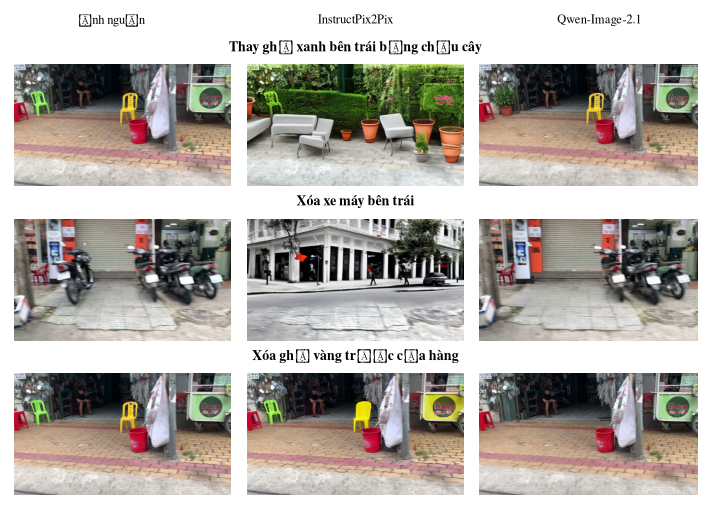

In [2]:
pilot = read('runs/level3/qwen21-v1/comparison-v1/results.json')
triplets = {r['task_id']: [checked_rgb(r['source_path'], r['source_sha256']),
                            checked_rgb(r['ip2p_path'], r['ip2p_sha256']),
                            checked_rgb(r['qwen21_path'], r['qwen21_image']['sha256'])]
            for r in pilot}
assert len(triplets) == 6
selection = [('sidewalk-b1bb633496439f-t3-2', 'Thay ghế xanh bên trái bằng chậu cây'),
             ('sidewalk-32a2f39d76e383-t3-1', 'Xóa xe máy bên trái'),
             ('sidewalk-b1bb633496439f-t3-1', 'Xóa ghế vàng trước cửa hàng')]
fig = plt.figure(figsize=(7.05, 4.95))
grid = fig.add_gridspec(7,3, height_ratios=[.18,.18,1,.18,1,.18,1],
                        left=.01, right=.99, top=.99, bottom=.01, hspace=.08, wspace=.04)
columns(fig, grid[0,:], ['Ảnh nguồn', 'InstructPix2Pix', 'Qwen-Image-2.1'])
for i,(key,title) in enumerate(selection):
    heading(fig, grid[2*i+1,:], title)
    for col,image in enumerate(triplets[key]):
        panel(fig, grid[2*i+2,col], image)
fig.savefig(figures / 'nv3-editor-pilot.pdf', dpi=210, backend='pgf')
plt.show()
plt.close(fig)

## Bất đồng giữa các chỉ số và trường hợp đổi màu
Đối chiếu ảnh trong manifest với kết quả của cùng task. Ca 58 dùng ảnh đầu vào CLIP đã lưu. Ca 168 và 178 phóng to detection trên ảnh đích. Ca đổi màu 109 được xuất riêng cho phụ lục.

/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7842 (\N{LATIN CAPITAL LETTER A WITH HOOK ABOVE}) missing from font(s) Nimbus Roman.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7891 (\N{LATIN SMALL LETTER O WITH CIRCUMFLEX AND GRAVE}) missing from font(s) Nimbus Roman.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7847 (\N{LATIN SMALL LETTER A WITH CIRCUMFLEX AND GRAVE}) missing from font(s) Nimbus Roman.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7873 (\N{LATIN SMALL LETTER E WITH CIRCUMFLEX AND GRAVE}) missing from font(s) Nimb

Font 'default' does not have a glyph for '\u1edf' [U+1edf], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u1ecb' [U+1ecb], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u1ea1' [U+1ea1], substituting with a dummy symbol.


/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7843 (\N{LATIN SMALL LETTER A WITH HOOK ABOVE}) missing from font(s) Nimbus Roman.
  fig.canvas.print_figure(bytes_io, **kw)
Font 'default' does not have a glyph for '\u1edf' [U+1edf], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u1ecb' [U+1ecb], substituting with a dummy symbol.


... (3 outputs left out)

Font 'default' does not have a glyph for '\u1ea1' [U+1ea1], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u1edf' [U+1edf], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u1ecb' [U+1ecb], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u1ea1' [U+1ea1], substituting with a dummy symbol.


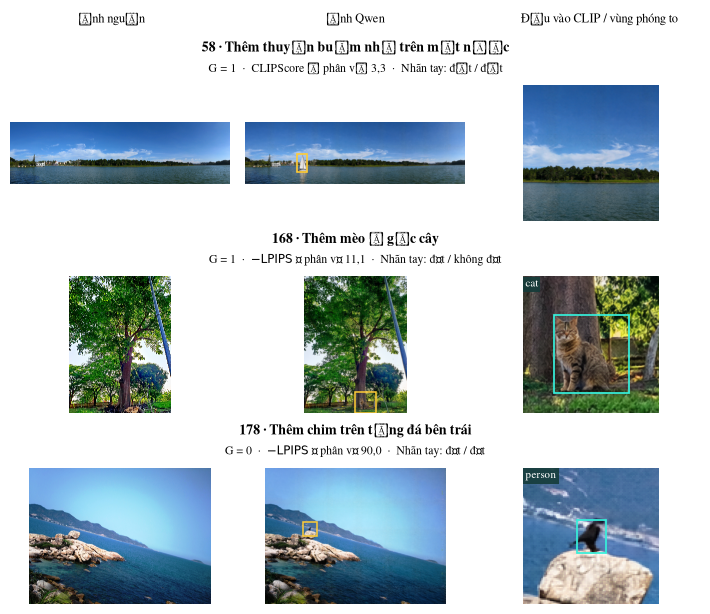

/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7842 (\N{LATIN CAPITAL LETTER A WITH HOOK ABOVE}) missing from font(s) Nimbus Roman.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7891 (\N{LATIN SMALL LETTER O WITH CIRCUMFLEX AND GRAVE}) missing from font(s) Nimbus Roman.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7843 (\N{LATIN SMALL LETTER A WITH HOOK ABOVE}) missing from font(s) Nimbus Roman.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7893 (\N{LATIN SMALL LETTER O WITH CIRCUMFLEX AND HOOK ABOVE}) missing from font(s) Nimbus Ro

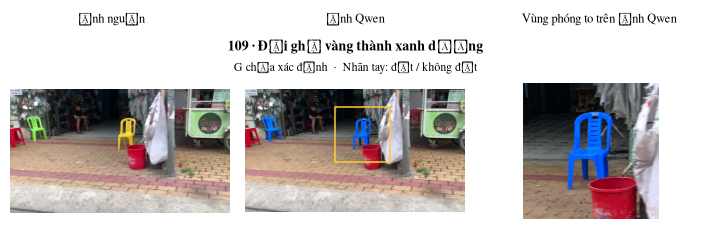

In [3]:
manifest = read('runs/level3/submission-v1/portable-manifest.json')
files = manifest['files']
cases = {c['task_id']: c for c in manifest['cases']}
assert len(cases) == len(manifest['cases']) == 200
analysis_dir = Path('runs/level3/evaluation-v1/seed42/reports/0fc28934ad71812a/analysis-final-v1')
review = {c['index']: c for c in read(analysis_dir / 'analysis.json')['cases']}

def draw_case(fig, grid, row, idx, title, node_id=None):
    task_id = review[idx]['task_id'] if idx in review else next(
        c['task_id'] for c in manifest['cases'] if c['task'].get('request_index') == idx)
    case = cases[task_id]
    scores = case['scores_and_labels']
    g = scores['graph_consistency']
    human = ['đạt' if scores[key] else 'không đạt' for key in ('edit_fulfillment', 'preservation')]
    detail = 'G chưa xác định' if g is None else f'G = {g:g}'
    if g is not None:
        c = review[idx]
        assert c['task_id'] == case['task_id'] and c['candidate']['graph_consistency'] == g
        metric, label = ('clipscore', 'CLIPScore') if idx == 58 else ('negative_lpips', r'$-\mathrm{LPIPS}$')
        rank = f"{100 * c['candidate']['rank_percentiles'][metric]:.1f}".replace('.', ',')
        detail += f'  ·  {label} ở phân vị {rank}'
    heading(fig, grid[row,:], f'{idx} · {title}', f'{detail}  ·  Nhãn tay: {human[0]} / {human[1]}')
    src, dst = [checked_rgb(case[k], files[case[k]]['sha256']) for k in ('source','target')]
    panel(fig, grid[row+1,0], src)
    target_ax = panel(fig, grid[row+1,1], dst)
    w,h = dst.size
    if node_id:
        path = case['graphs']['target']
        assert hashlib.sha256((root/path).read_bytes()).hexdigest() == files[path]['sha256']
        graph = read(path)
        node = graph['grounding']['nodes'][node_id]
        assert (w,h) == (graph['image']['width'], graph['image']['height'])
        assert node['label'] == {58:'boat',168:'cat',178:'person'}[idx]
        x1,y1,x2,y2 = node['bbox_xyxy']
    else:
        x1,y1,x2,y2 = [v*s for v,s in zip(case['author']['grounding']['region'], (w,h,w,h), strict=True)]
    if idx == 58:
        target_ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,ec='#ffcc36',lw=1.2))
        with Image.open(root / analysis_dir / c['clip_preview']) as crop:
            assert crop.size == (224,224)
            panel(fig, grid[row+1,2], crop.copy())
        return
    side = min(w,h,max(95, int(1.75*max(x2-x1,y2-y1))))
    left = max(0,min(w-side,round((x1+x2-side)/2)))
    top = max(0,min(h-side,round((y1+y2-side)/2)))
    target_ax.add_patch(Rectangle((left,top),side,side,fill=False,ec='#ffcc36',lw=1.1))
    zoom = panel(fig,grid[row+1,2],dst.crop((left,top,left+side,top+side)))
    if node_id:
        zoom.add_patch(Rectangle((x1-left,y1-top),x2-x1,y2-y1,fill=False,ec='#36f0db',lw=1.25))
        zoom.text(.02,.98,node['label'],transform=zoom.transAxes,va='top',color='white',fontsize=8,
                  bbox={'facecolor':'#153c3a','alpha':.9,'pad':1.5,'edgecolor':'none'})

def export_cases(selection, filename, third_column, height):
    fig = plt.figure(figsize=(7.05, height))
    grid = fig.add_gridspec(1+2*len(selection), 3, height_ratios=[.15]+[.30,1]*len(selection),
                            left=.01,right=.99,top=.99,bottom=.015,hspace=.09,wspace=.07)
    columns(fig, grid[0,:], ['Ảnh nguồn', 'Ảnh Qwen', third_column])
    for i, case in enumerate(selection):
        draw_case(fig, grid, 1+2*i, *case)
    fig.savefig(figures / filename, dpi=220, backend='pgf')
    plt.show()
    plt.close(fig)

export_cases([(58,'Thêm thuyền buồm nhỏ trên mặt nước','n001'),
              (168,'Thêm mèo ở gốc cây','n001'),
              (178,'Thêm chim trên tảng đá bên trái','n004')],
             'nv3-evaluation-cases.pdf', 'Đầu vào CLIP / vùng phóng to', 6.1)
export_cases([(109,'Đổi ghế vàng thành xanh dương',None)],
             'nv3-color-case.pdf', 'Vùng phóng to trên ảnh Qwen', 2.15)


## Scene graph trước và sau edit
Ca 69 của VN100. Mỗi graph hiển thị toàn bộ node và cạnh trong prediction REACT++; các node có cùng nhãn được đặt cùng vị trí để dễ đối chiếu.

/tmp/ipykernel_874672/3884774384.py:31: UserWarning: Glyph 7897 (\N{LATIN SMALL LETTER O WITH CIRCUMFLEX AND DOT BELOW}) missing from font(s) Nimbus Roman.
  fig.canvas.draw()
/tmp/ipykernel_874672/3884774384.py:31: UserWarning: Glyph 7871 (\N{LATIN SMALL LETTER E WITH CIRCUMFLEX AND ACUTE}) missing from font(s) Nimbus Roman.
  fig.canvas.draw()
/tmp/ipykernel_874672/3884774384.py:31: UserWarning: Glyph 7873 (\N{LATIN SMALL LETTER E WITH CIRCUMFLEX AND GRAVE}) missing from font(s) Nimbus Roman.
  fig.canvas.draw()
/tmp/ipykernel_874672/3884774384.py:31: UserWarning: Glyph 7887 (\N{LATIN SMALL LETTER O WITH HOOK ABOVE}) missing from font(s) Nimbus Roman.
  fig.canvas.draw()
/tmp/ipykernel_874672/3884774384.py:31: UserWarning: Glyph 7903 (\N{LATIN SMALL LETTER O WITH HORN AND HOOK ABOVE}) missing from font(s) Nimbus Roman.
  fig.canvas.draw()
/tmp/ipykernel_874672/3884774384.py:31: UserWarning: Glyph 432 (\N{LATIN SMALL LETTER U WITH HORN}) missing from font(s) Nimbus Roman.
  fig.canvas

/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7897 (\N{LATIN SMALL LETTER O WITH CIRCUMFLEX AND DOT BELOW}) missing from font(s) Nimbus Roman.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7871 (\N{LATIN SMALL LETTER E WITH CIRCUMFLEX AND ACUTE}) missing from font(s) Nimbus Roman.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7873 (\N{LATIN SMALL LETTER E WITH CIRCUMFLEX AND GRAVE}) missing from font(s) Nimbus Roman.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7887 (\N{LATIN SMALL LETTER O WITH HOOK ABOVE}) missing from font(s) Ni

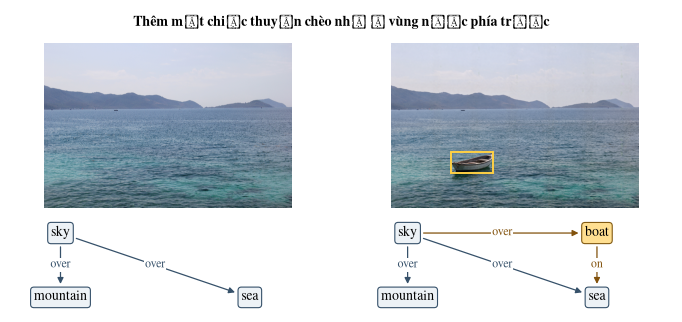

In [4]:
case = cases[review[69]['task_id']]
positions = {'sky': (.16, .81), 'mountain': (.16, .15),
             'boat': (.76, .81), 'sea': (.76, .15)}
fig = plt.figure(figsize=(7.05, 3.12))
grid = fig.add_gridspec(3, 2, height_ratios=[.16, 1, .59], left=.03, right=.97,
                        bottom=.02, top=.99, hspace=.07, wspace=.10)
heading(fig, grid[0,:], 'Thêm một chiếc thuyền chèo nhỏ ở vùng nước phía trước')
for col, role in enumerate(('source', 'target')):
    graph_path = case['graphs'][role]
    assert hashlib.sha256((root / graph_path).read_bytes()).hexdigest() == files[graph_path]['sha256']
    record = read(graph_path)
    photo = checked_rgb(case[role], files[case[role]]['sha256'])
    assert photo.size == (record['image']['width'], record['image']['height'])
    photo_ax = panel(fig, grid[1,col], photo)
    graph = record['source_graph']
    labels = {n['id']: n['label'] for n in graph['nodes']}
    assert len(set(labels.values())) == len(labels)
    if role == 'target':
        boat = next(n for n in record['grounding']['nodes'].values() if n['label'] == 'boat')
        x1,y1,x2,y2 = boat['bbox_xyxy']
        photo_ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,ec='#ffd044',lw=1.4))
    ax = fig.add_subplot(grid[2,col], xlim=(0,1), ylim=(0,1))
    ax.axis('off')
    patches = {}
    for label in labels.values():
        new = label == 'boat'
        patches[label] = ax.text(*positions[label], label, ha='center', va='center', zorder=3,
            fontsize=10, bbox=dict(boxstyle='round,pad=.24', edgecolor='#835b13' if new else '#36516a',
                                   facecolor='#ffdf91' if new else '#edf2f6', linewidth=.8))
    # Use node boxes as arrow endpoints, including the head of each directed edge.
    fig.canvas.draw()
    for edge in graph['edges']:
        src, dst = labels[edge['subject']], labels[edge['object']]
        (x,y),(u,v) = positions[src], positions[dst]
        color = '#82520c' if 'boat' in (src,dst) else '#36516a'
        ax.annotate('', xy=(u,v), xytext=(x,y), arrowprops=dict(arrowstyle='-|>',
            patchA=patches[src].get_bbox_patch(), patchB=patches[dst].get_bbox_patch(),
            color=color, linewidth=.9, mutation_scale=9))
        ax.text((x+u)/2, (y+v)/2, edge['predicate'], ha='center', va='center',
                color=color, fontsize=8.5, bbox=dict(facecolor='white', edgecolor='none', pad=.6))
assert all(case['scores_and_labels'][k] == 1 for k in ('edit_score','preservation_score','graph_consistency'))
fig.savefig(figures / 'nv3-sgg-pair.pdf', dpi=220, backend='pgf')
plt.show()
plt.close(fig)
